# Forecast Using Tabby

In [1]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q timecopilot

TimeCopilot ships a `Tabby` class for [Huawei Paris Noah's Ark Lab](https://huggingface.co/paris-noah)'s [Tabby](https://huggingface.co/paris-noah/Tabby) model ([arXiv:2609.13956](https://arxiv.org/abs/2609.13956)):

| Checkpoint | `repo_id` | Parameters | Native quantiles |
|------------|-----------|------------|------------------|
| **Tabby** (default) | `paris-noah/Tabby` | ~147M | 99 (0.01–0.99) |

The released weights are a frozen pretrained patch-transformer backbone plus a small prompt module, loaded with `transformers.AutoModel` and `trust_remote_code=True`. Tabby forecasts each series independently. Its backbone window is 8,192 steps; for a horizon `H` it masks `max(H, 128)` future positions, so it uses at most `8192 - max(H, 128)` observed steps of history (the default `context_length` is 8,096, the published GIFT-Eval input cap).

**Benchmarks and license:** the prompt was trained on GIFT-Eval *training* tasks, so the [GIFT-Eval](https://huggingface.co/spaces/Salesforce/GIFT-Eval) leaderboard flags the submission as `testdata_leakage: Yes` (MASE 0.688, CRPS 0.476). The weights are released under [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/) (non-commercial).

**Prediction intervals:** pass any `level` or `quantiles`. Values between the 99 native knots are linearly interpolated; the median (0.5) is the point forecast.

In this example we cross-validate Tabby with its published inference settings (`precision="bf16"`, the default, which runs bfloat16 autocast on GPU) on event pageview data. Pass `precision="fp32"` to keep the whole forward pass in float32.

## Import libraries

In [2]:
import pandas as pd

from timecopilot import TimeCopilotForecaster

## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)

The pandas frequency will be inferred from the ds column, if not provided.
If the seasonality is not provided, it will be inferred based on the frequency.
If the horizon is not set, it will default to 2 times the inferred seasonality.

In [3]:
df = pd.read_csv(
    "https://timecopilot.s3.amazonaws.com/public/data/events_pageviews.csv",
    parse_dates=["ds"],
)
df.head()

,unique_id,ds,y
0,Oktoberfest,2020-01-31,25376
1,Oktoberfest,2020-02-29,28470
2,Oktoberfest,2020-03-31,23816
3,Oktoberfest,2020-04-30,46186
4,Oktoberfest,2020-05-31,31213


## Plot the data

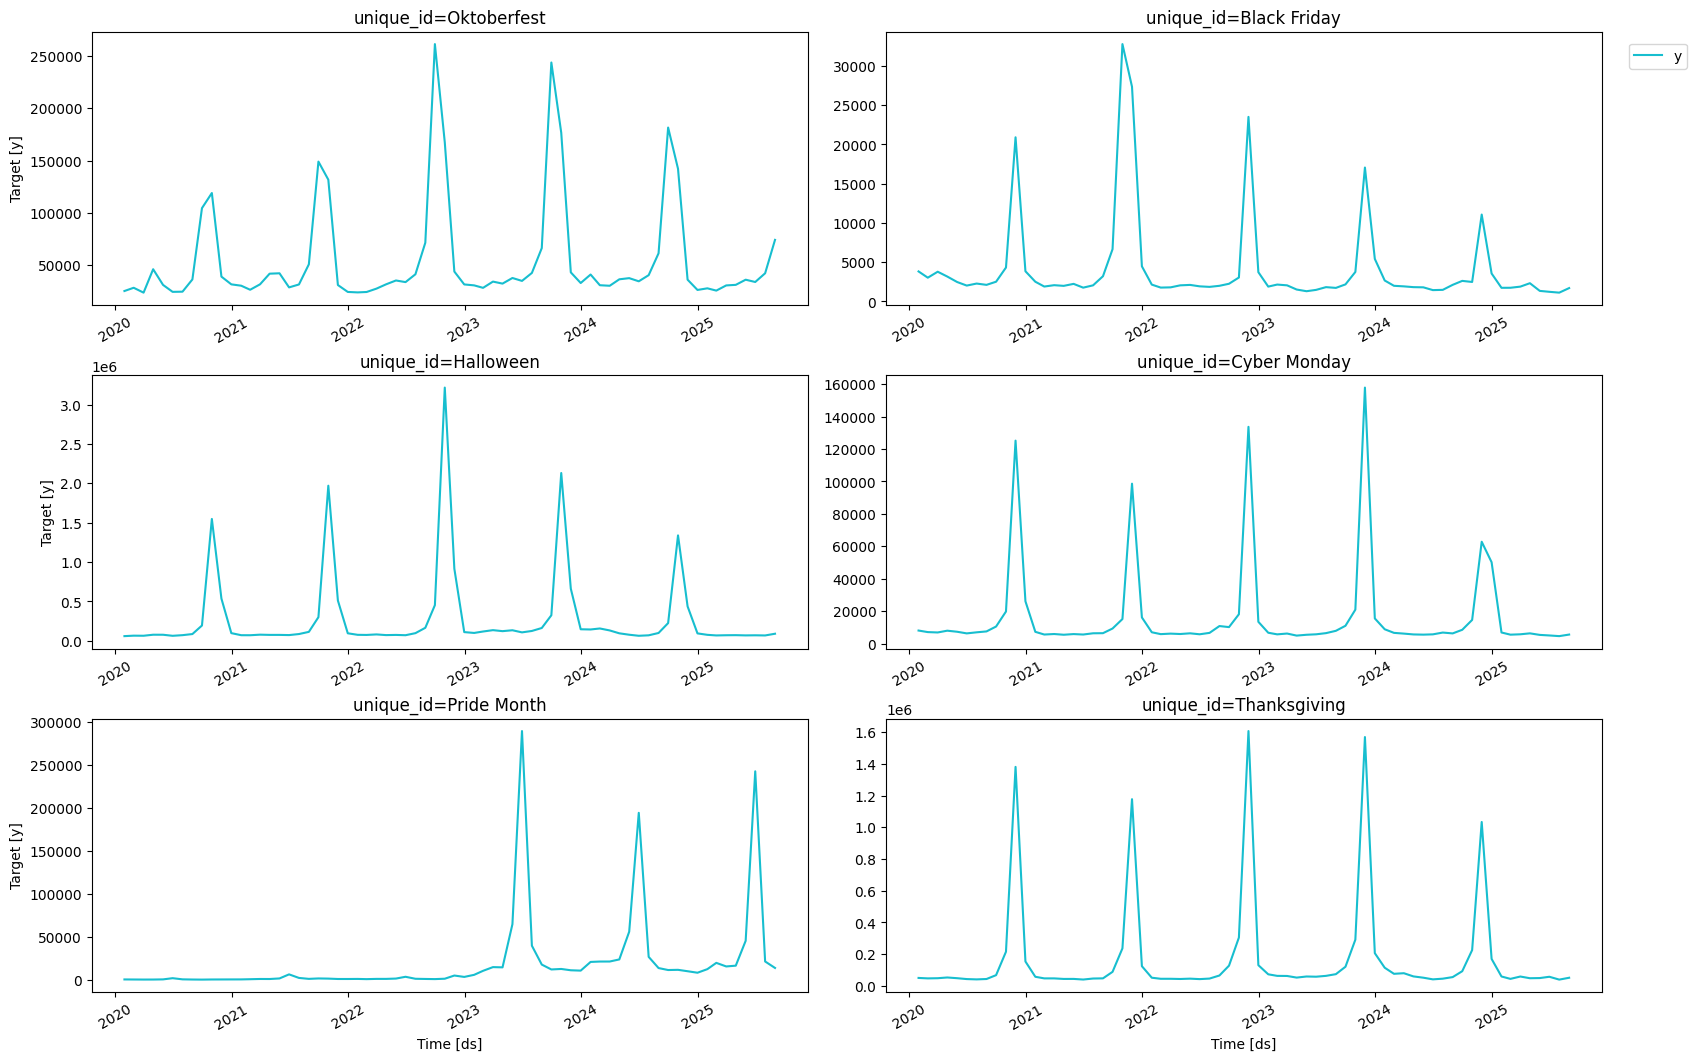

In [4]:
TimeCopilotForecaster.plot(df)

## Import the models

In [5]:
from timecopilot.models.foundation import Tabby

## Create a TimeCopilotForecaster

In [12]:
models = [
    Tabby(alias="Tabby", precision="bf16"),
]

tcf = TimeCopilotForecaster(models=models)

## Generate forecast

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly)
- h: The forecast horizon, which is the number of periods to predict
- seasonality: The seasonal period of your data, which can be inferred if not provided
- level: Prediction interval levels (percent)

In [13]:
level = [70, 80, 90]
cv_df = tcf.cross_validation(df=df, h=12, level=level)

0it [00:00, ?it/s]
100%|██████████| 1/1 [00:00<00:00,  1.39it/s]
1it [00:00,  1.34it/s]


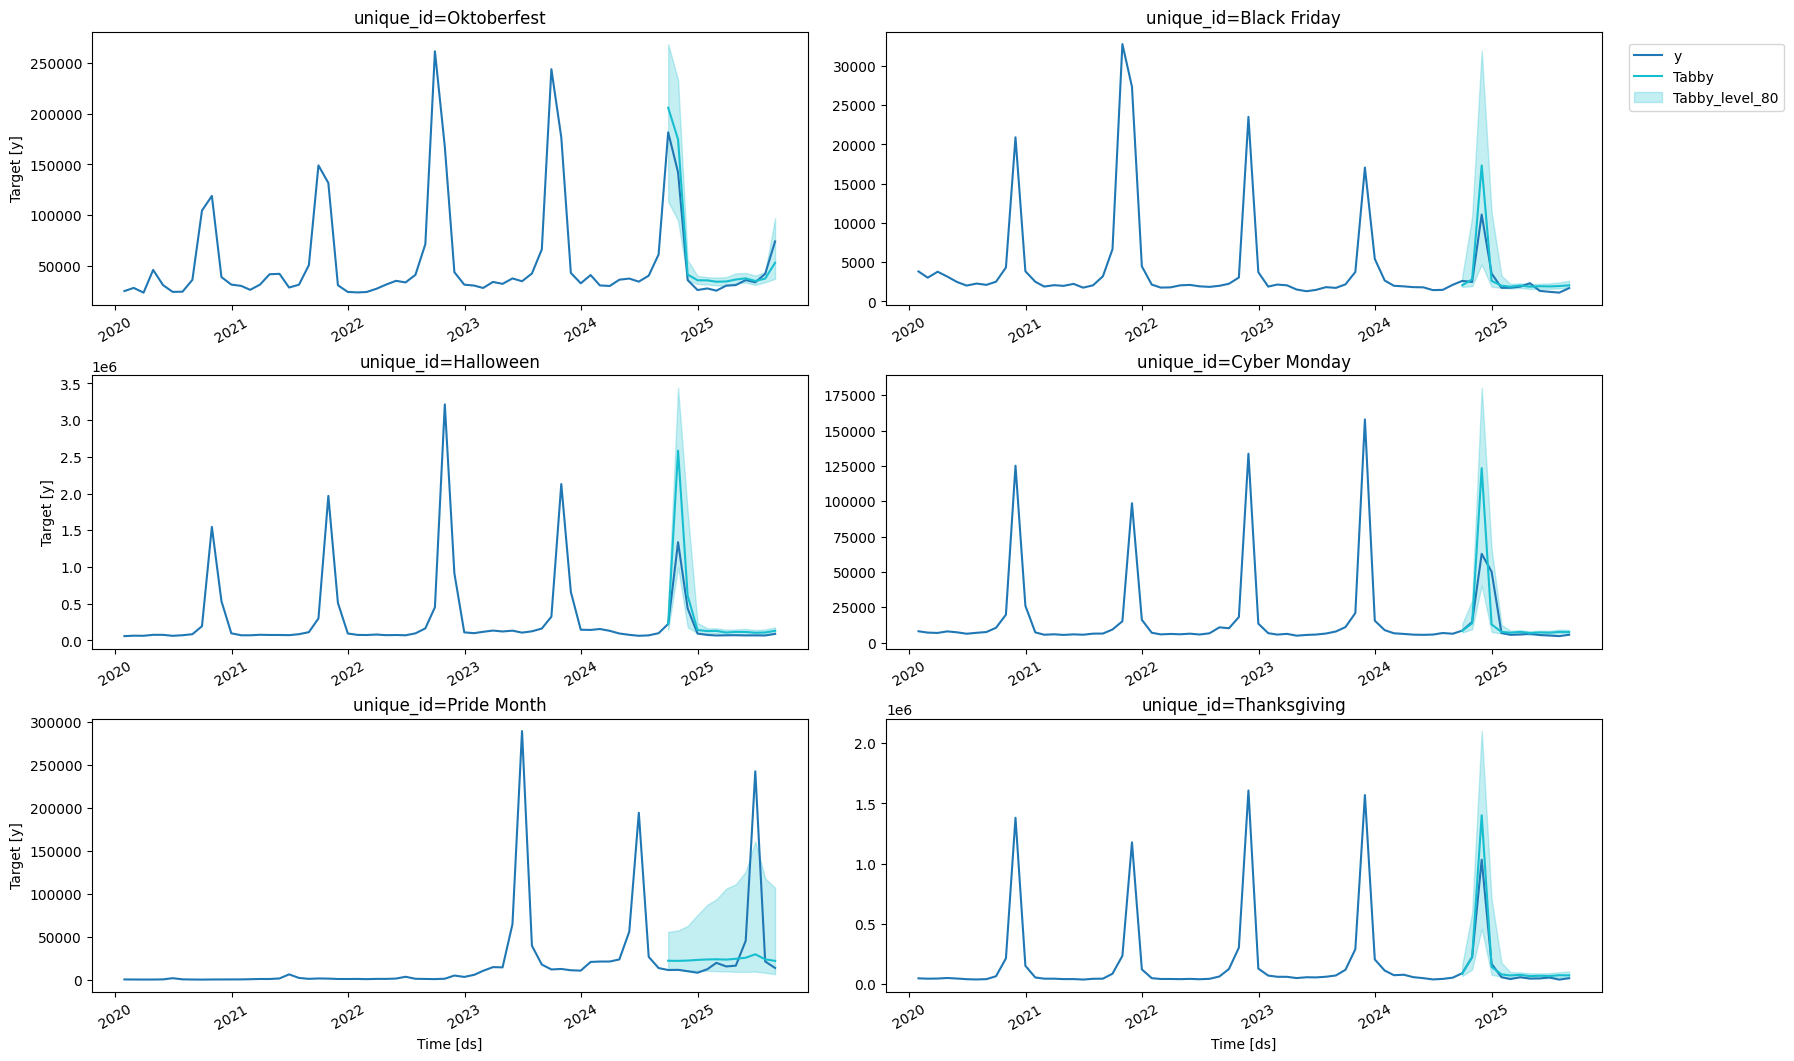

In [14]:
tcf.plot(df, cv_df.drop(columns=["cutoff", "y"]), level=[80])

In [15]:
cv_df.head()

,unique_id,ds,cutoff,y,Tabby,Tabby-lo-70,Tabby-hi-70,Tabby-lo-80,Tabby-hi-80,Tabby-lo-90,Tabby-hi-90
0,Black Friday,2024-09-30,2024-08-31,2607,2049.376953,1885.861084,2417.204590,1829.213135,3157.957520,1635.378662,4907.942383
1,Black Friday,2024-10-31,2024-08-31,2470,2799.265625,2112.763916,6688.913086,1944.557129,10753.810547,1658.874023,15823.072266
2,Black Friday,2024-11-30,2024-08-31,11058,17316.138672,6185.125000,30406.574219,4700.687988,31946.658203,3869.626221,36169.101562
3,Black Friday,2024-12-31,2024-08-31,3548,2613.249512,1982.492188,9025.923828,1853.736572,11381.388672,1626.874023,17560.091797
4,Black Friday,2025-01-31,2024-08-31,1724,1995.891602,1795.692383,2534.376953,1729.608887,3263.395996,1518.588623,5472.529785


## Evaluation

In [16]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mase, scaled_crps

In [17]:
eval_df = evaluate(
    cv_df.drop(columns=["cutoff"]),
    train_df=df.query("ds <= '2024-08-31'"),
    metrics=[partial(mase, seasonality=12), scaled_crps],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.sort_values(
    by="scaled_crps"
).round(3)

metric,mase,scaled_crps
Tabby,1.541,0.214
